Ali Hisham AlJamed 2240005868 7MA1 / MA01

Procedural steps (Tasks):

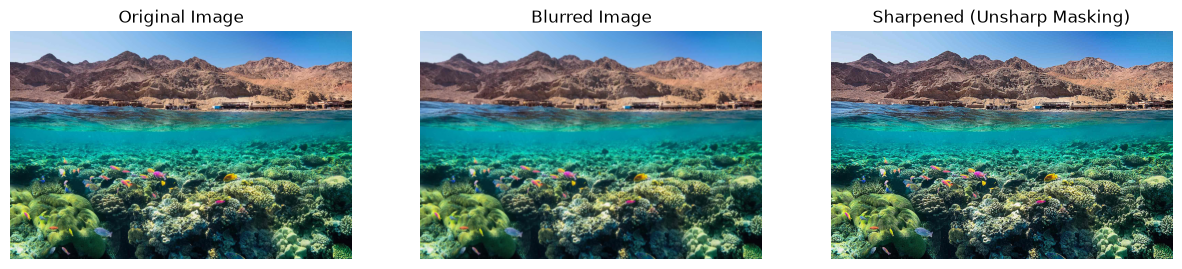

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
# Read the image

image = cv2.imread('Red_Sea.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # Convert from BGR to RGB

# Gaussian sigma

sigma=2

#parameter

amount=1.5

# Convert image to float32 for processing

image_float = image.astype(np.float32) / 255.0

# Apply Gaussian blur

blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma,sigmaY=sigma)

# Perform Unsharp Masking

sharpened = np.clip(image_float + amount * (image_float - blurred), 0,1)

# Plot original, blurred, and sharpened images

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(blurred)
ax[1].set_title("Blurred Image")
ax[1].axis("off")
ax[2].imshow(sharpened)
ax[2].set_title("Sharpened (Unsharp Masking)")
ax[2].axis("off")
plt.show()

Assessment Tasks:

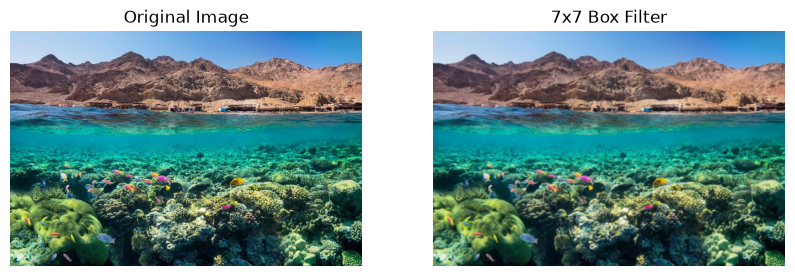

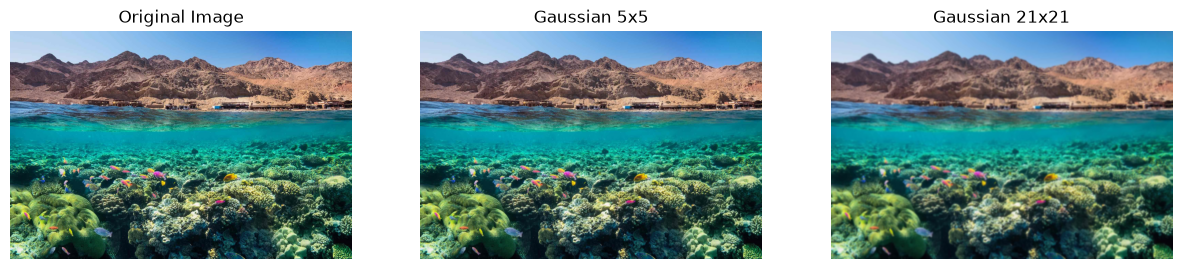

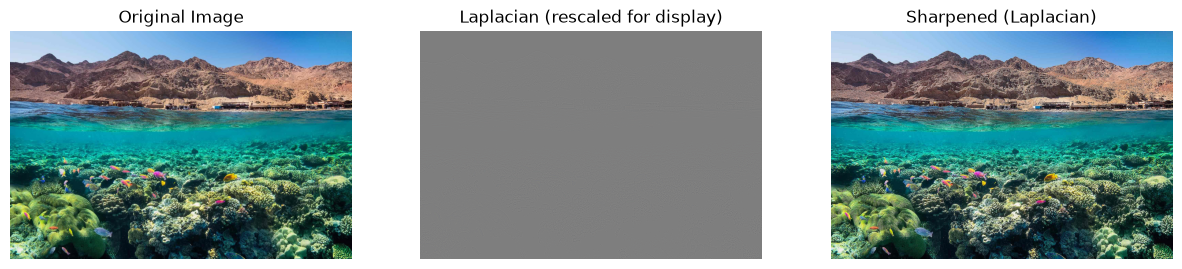

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read the image
image = cv2.imread('Red_Sea.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB

# Convert image to float32 for processing
image_float = image.astype(np.float32) / 255.0

# Task 1: 7x7 box filter
kernel_box = np.ones((7, 7), np.float32) / (7 * 7)   # each weight = 1/49
box_smoothed = cv2.filter2D(image_float, -1, kernel_box)
# (equivalent: cv2.blur(image_float, (7, 7)))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(np.clip(box_smoothed, 0, 1))
ax[1].set_title("7x7 Box Filter")
ax[1].axis("off")
plt.show()

# Task 2: 5x5 and 21x21 Gaussian filters
# sigma = 0 lets OpenCV compute sigma from the kernel size
gauss_5 = cv2.GaussianBlur(image_float, (5, 5), 0)
gauss_21 = cv2.GaussianBlur(image_float, (21, 21), 0)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(gauss_5)
ax[1].set_title("Gaussian 5x5")
ax[1].axis("off")
ax[2].imshow(gauss_21)
ax[2].set_title("Gaussian 21x21")
ax[2].axis("off")
plt.show()

# Task 3: 3x3 Laplacian sharpening
# ksize=1 -> the classic 3x3 kernel [[0,1,0],[1,-4,1],[0,1,0]]
laplacian = cv2.Laplacian(image_float, cv2.CV_32F, ksize=1)

# Sharpen: subtract the Laplacian (center coefficient is negative)
sharpened_lap = np.clip(image_float - laplacian, 0, 1)

# Laplacian has negative values, so rescale to [0,1] just for display
lap_display = (laplacian - laplacian.min()) / (laplacian.max() - laplacian.min())

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(lap_display)
ax[1].set_title("Laplacian (rescaled for display)")
ax[1].axis("off")
ax[2].imshow(sharpened_lap)
ax[2].set_title("Sharpened (Laplacian)")
ax[2].axis("off")
plt.show()
